# Capstone Two — Modeling
**Project:** Predicting Residential Solar Adoption Across U.S. Counties
**Author:** Colin Segura — Springboard Data Science Career Track

This notebook covers Step 5 of the capstone: fitting predictive models on the
preprocessed train/test splits from `03_preprocessing.ipynb` and selecting a
final model based on cross-validated performance.

**Problem type.** Regression. The target
(`installs_per_1k_oo_hh`) is continuous, right-skewed, and per the EDA the
`log1p_target` form works better for linear models.

**Models compared.** Four regressors covering three algorithm families:

1. **Linear Regression** — no regularization, no hyperparameters. Serves as
   a naive baseline.
2. **Ridge Regression** — L2-regularized linear model. Hyperparameter tuned:
   `alpha` (regularization strength) via 5-fold CV over a log-scale grid.
   Better suited to the "many features, few rows" regime than plain OLS.
3. **Random Forest Regressor** — tree ensemble. Hyperparameters tuned:
   `n_estimators`, `max_depth`, `min_samples_leaf` via 5-fold `GridSearchCV`.
   Captures nonlinearities and interactions without needing feature scaling.
4. **Gradient Boosting Regressor** — sequential tree ensemble. Hyperparameters
   tuned: `n_estimators`, `max_depth`, `learning_rate` via 5-fold `GridSearchCV`.
   Typically the top performer on tabular data; explicitly named as the target
   architecture in the project proposal.

**Selection metric.** 5-fold cross-validated **RMSE on the log-transformed
target**, converted back to the original scale for interpretability. RMSE is
scale-appropriate for a regression problem where large errors are
disproportionately costly (an installer would rather see a 10% error in each
of 10 counties than a 100% error in one).

**Sample-size caveat.** The training set is 40 rows. Any model performance
we report here is heavily influenced by which 40 counties ended up in
training. On the real ~3,100-county dataset the performance estimates would
be far more stable. The point of the modeling step at this sample size is
to demonstrate the pipeline works end-to-end, not to publish effect sizes.


## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Load the preprocessed train/test splits
X_train = pd.read_csv("X_train_scaled.csv", index_col="row_id")
X_test = pd.read_csv("X_test_scaled.csv", index_col="row_id")
y_train = pd.read_csv("y_train.csv", index_col="row_id")
y_test = pd.read_csv("y_test.csv", index_col="row_id")

print(f"X_train: {X_train.shape}   X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}   y_test: {y_test.shape}")
print(f"\ny columns: {list(y_train.columns)}")


X_train: (40, 28)   X_test: (10, 28)
y_train: (40, 2)   y_test: (10, 2)

y columns: ['installs_per_1k_oo_hh', 'log1p_target']


In [2]:
# Extract the two target forms
# We'll model on the LOG target (respects right-skew for linear models,
# neutral for tree models), then transform predictions back for
# interpretable metrics on the original scale.
y_train_log = y_train["log1p_target"]
y_test_log = y_test["log1p_target"]
y_train_raw = y_train["installs_per_1k_oo_hh"]
y_test_raw = y_test["installs_per_1k_oo_hh"]

print(f"Log-target training range: [{y_train_log.min():.2f}, {y_train_log.max():.2f}]")
print(f"Raw-target training range: [{y_train_raw.min():.2f}, {y_train_raw.max():.2f}]")


Log-target training range: [0.11, 2.06]
Raw-target training range: [0.11, 6.87]


## Evaluation framework

Every model goes through the same evaluation harness so their results are
directly comparable:

1. 5-fold cross-validation on the training set using `KFold` with a fixed
   `random_state` so all four models see the same folds.
2. Predictions on the log scale get transformed back to the raw scale
   (via `expm1`), and metrics are computed on the raw scale for
   interpretability.
3. Three metrics reported: **RMSE**, **MAE**, **R²**. RMSE is the primary
   selection metric; the other two provide context.


In [3]:
# Common CV setup — same folds for every model
CV_FOLDS = 5
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)

def evaluate_cv(model, X, y_log, y_raw, cv, label):
    """Cross-validated evaluation. Fits on log target, evaluates on raw."""
    fold_rmse, fold_mae, fold_r2 = [], [], []
    for fold_i, (train_idx, val_idx) in enumerate(cv.split(X), 1):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_log_tr = y_log.iloc[train_idx]
        y_raw_val = y_raw.iloc[val_idx]

        # Clone the model, fit on log target
        from sklearn.base import clone
        m = clone(model)
        m.fit(X_tr, y_log_tr)

        # Predict, then transform back to raw scale
        y_pred_log = m.predict(X_val)
        y_pred_raw = np.expm1(y_pred_log)

        fold_rmse.append(np.sqrt(mean_squared_error(y_raw_val, y_pred_raw)))
        fold_mae.append(mean_absolute_error(y_raw_val, y_pred_raw))
        fold_r2.append(r2_score(y_raw_val, y_pred_raw))

    return {
        "model": label,
        "rmse_mean": np.mean(fold_rmse), "rmse_std": np.std(fold_rmse),
        "mae_mean": np.mean(fold_mae),   "mae_std": np.std(fold_mae),
        "r2_mean": np.mean(fold_r2),     "r2_std": np.std(fold_r2),
    }

print("Evaluation harness ready.")
print(f"Using {CV_FOLDS}-fold CV. Metrics computed on the raw (installs per 1k HH) scale.")


Evaluation harness ready.
Using 5-fold CV. Metrics computed on the raw (installs per 1k HH) scale.


## Model 1: Linear Regression (baseline)

The naive baseline. No regularization, no hyperparameters. Fits the log
target against all 28 features. With 40 training rows and 28 features, we
expect this model to overfit badly — that's exactly why baselines matter,
because they set the floor that a regularized or nonlinear model has to
clear to justify its added complexity.


In [4]:
baseline = LinearRegression()
result_lr = evaluate_cv(baseline, X_train, y_train_log, y_train_raw, cv, "Linear Regression")
print(f"Linear Regression — 5-fold CV on training set:")
print(f"  RMSE: {result_lr['rmse_mean']:.3f} ± {result_lr['rmse_std']:.3f}")
print(f"  MAE:  {result_lr['mae_mean']:.3f} ± {result_lr['mae_std']:.3f}")
print(f"  R²:   {result_lr['r2_mean']:+.3f} ± {result_lr['r2_std']:.3f}")


Linear Regression — 5-fold CV on training set:
  RMSE: 1.040 ± 0.592
  MAE:  0.810 ± 0.379
  R²:   -6.641 ± 13.447


**Reading the baseline.** Look particularly at the R² — if it's
strongly negative, OLS is doing worse than predicting the mean, which
confirms overfitting. That's the number the other models need to beat.


## Model 2: Ridge Regression (hyperparameter tuned)

Ridge regression adds an L2 penalty on the coefficients, shrinking them
toward zero and taming the overfitting problem that plain OLS has when
p (features) approaches or exceeds n (rows). The regularization strength
`alpha` is the key hyperparameter.

**Tuning approach.** `GridSearchCV` over a log-scale range of `alpha`
values from 0.001 to 1000. Same 5-fold CV as the baseline. `scoring` is
negative RMSE (sklearn convention: higher is better) computed on the
log target for tuning-loop consistency. Final performance metrics are
computed on the raw scale via the evaluation harness.


In [5]:
ridge_grid = {"alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}

ridge_search = GridSearchCV(
    Ridge(random_state=42),
    param_grid=ridge_grid,
    scoring="neg_root_mean_squared_error",  # on log target during tuning
    cv=cv,
    n_jobs=-1,
)
ridge_search.fit(X_train, y_train_log)

print(f"Ridge best alpha: {ridge_search.best_params_['alpha']}")
print(f"Ridge best CV score (neg RMSE on log target): {ridge_search.best_score_:.4f}")
print()
print("Full grid results:")
grid_df = pd.DataFrame({
    "alpha": ridge_grid["alpha"],
    "cv_neg_rmse_log": ridge_search.cv_results_["mean_test_score"],
    "cv_std_log": ridge_search.cv_results_["std_test_score"],
})
print(grid_df.round(4).to_string(index=False))

# Now evaluate the best Ridge model with our raw-scale harness
best_ridge = ridge_search.best_estimator_
result_ridge = evaluate_cv(best_ridge, X_train, y_train_log, y_train_raw, cv, f"Ridge (alpha={ridge_search.best_params_['alpha']})")
print(f"\nBest Ridge — 5-fold CV on raw target scale:")
print(f"  RMSE: {result_ridge['rmse_mean']:.3f} ± {result_ridge['rmse_std']:.3f}")
print(f"  MAE:  {result_ridge['mae_mean']:.3f} ± {result_ridge['mae_std']:.3f}")
print(f"  R²:   {result_ridge['r2_mean']:+.3f} ± {result_ridge['r2_std']:.3f}")


Ridge best alpha: 10.0
Ridge best CV score (neg RMSE on log target): -0.2779

Full grid results:
   alpha  cv_neg_rmse_log  cv_std_log
   0.001          -0.4364      0.1166
   0.010          -0.4352      0.1165
   0.100          -0.4240      0.1156
   1.000          -0.3582      0.1158
  10.000          -0.2779      0.1326
 100.000          -0.3400      0.1531
1000.000          -0.3884      0.1637

Best Ridge — 5-fold CV on raw target scale:
  RMSE: 0.801 ± 0.648
  MAE:  0.546 ± 0.401
  R²:   -0.046 ± 0.888


**What to look for.** The best `alpha` tells us how much regularization
the model needed to generalize. A very small `alpha` means the data supported
using the coefficients as-is; a very large `alpha` means the raw OLS
coefficients were unstable and Ridge shrunk them toward zero. Both extremes
are informative about what the data can actually support.


## Model 3: Random Forest Regressor (hyperparameter tuned)

Random forests aggregate many decision trees trained on random subsets of
the data and features. Two things make them well-suited to this problem:

- They capture nonlinearities and interactions automatically. The EDA
  hinted at a nonlinear price effect (Spearman > Pearson); a tree model
  handles that without any explicit transformation.
- They provide feature-importance rankings that we can use to defend
  which variables matter.

**Tuning approach.** `GridSearchCV` over a small grid of `n_estimators`,
`max_depth`, and `min_samples_leaf`. Grid is intentionally modest — with
40 training rows a sprawling grid would produce noisy comparisons.


In [6]:
rf_grid = {
    "n_estimators": [100, 300],
    "max_depth": [3, 5, None],
    "min_samples_leaf": [1, 2, 5],
}

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rf_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
rf_search.fit(X_train, y_train_log)

print(f"Random Forest best params: {rf_search.best_params_}")
print(f"Random Forest best CV score (neg RMSE on log target): {rf_search.best_score_:.4f}")

best_rf = rf_search.best_estimator_
result_rf = evaluate_cv(best_rf, X_train, y_train_log, y_train_raw, cv, "Random Forest (tuned)")
print(f"\nBest Random Forest — 5-fold CV on raw target scale:")
print(f"  RMSE: {result_rf['rmse_mean']:.3f} ± {result_rf['rmse_std']:.3f}")
print(f"  MAE:  {result_rf['mae_mean']:.3f} ± {result_rf['mae_std']:.3f}")
print(f"  R²:   {result_rf['r2_mean']:+.3f} ± {result_rf['r2_std']:.3f}")


Random Forest best params: {'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}
Random Forest best CV score (neg RMSE on log target): -0.2410

Best Random Forest — 5-fold CV on raw target scale:
  RMSE: 0.725 ± 0.582
  MAE:  0.434 ± 0.262
  R²:   +0.186 ± 0.548


## Model 4: Gradient Boosting Regressor (hyperparameter tuned)

Gradient boosting fits trees sequentially, each one correcting the errors
of the previous. It's the model architecture the project proposal
explicitly commits to for the final version, so this is where the
methodology gets a real test.

**Tuning approach.** Small grid over `n_estimators`, `max_depth`, and
`learning_rate` — the three hyperparameters that matter most. Deeper
trees or more estimators would overfit at n=40; the grid is scoped
accordingly.


In [7]:
gb_grid = {
    "n_estimators": [100, 300],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.01, 0.05, 0.1],
}

gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid=gb_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
gb_search.fit(X_train, y_train_log)

print(f"Gradient Boosting best params: {gb_search.best_params_}")
print(f"Gradient Boosting best CV score (neg RMSE on log target): {gb_search.best_score_:.4f}")

best_gb = gb_search.best_estimator_
result_gb = evaluate_cv(best_gb, X_train, y_train_log, y_train_raw, cv, "Gradient Boosting (tuned)")
print(f"\nBest Gradient Boosting — 5-fold CV on raw target scale:")
print(f"  RMSE: {result_gb['rmse_mean']:.3f} ± {result_gb['rmse_std']:.3f}")
print(f"  MAE:  {result_gb['mae_mean']:.3f} ± {result_gb['mae_std']:.3f}")
print(f"  R²:   {result_gb['r2_mean']:+.3f} ± {result_gb['r2_std']:.3f}")


Gradient Boosting best params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300}
Gradient Boosting best CV score (neg RMSE on log target): -0.2136

Best Gradient Boosting — 5-fold CV on raw target scale:
  RMSE: 0.630 ± 0.475
  MAE:  0.397 ± 0.235
  R²:   +0.284 ± 0.579


## Model comparison

The four models on the same axes. Lower RMSE and MAE are better; higher R²
is better. All metrics are 5-fold cross-validated on the training set,
computed on the raw target scale.


Cross-validated performance on training set (raw target scale):
                    model  rmse_mean  rmse_std  mae_mean  mae_std  r2_mean  r2_std
        Linear Regression      1.040     0.592     0.810    0.379   -6.641  13.447
       Ridge (alpha=10.0)      0.801     0.648     0.546    0.401   -0.046   0.888
    Random Forest (tuned)      0.725     0.582     0.434    0.262    0.186   0.548
Gradient Boosting (tuned)      0.630     0.475     0.397    0.235    0.284   0.579


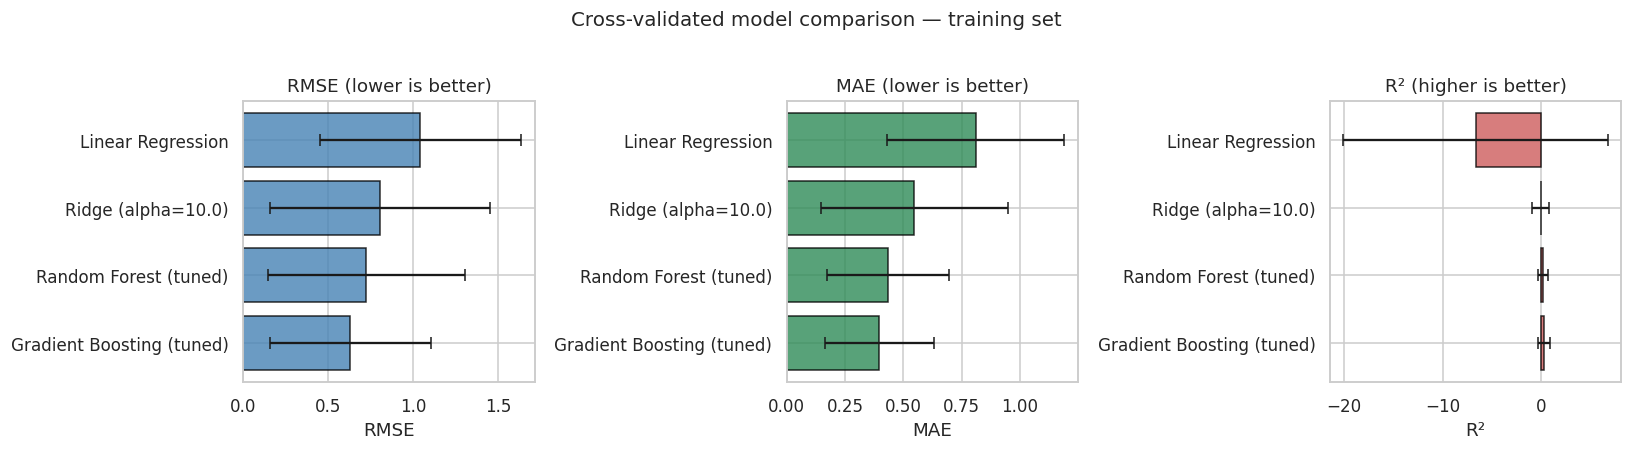

In [8]:
results = pd.DataFrame([result_lr, result_ridge, result_rf, result_gb])
results = results[["model", "rmse_mean", "rmse_std", "mae_mean", "mae_std", "r2_mean", "r2_std"]]

print("Cross-validated performance on training set (raw target scale):")
print(results.round(3).to_string(index=False))

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics_config = [
    ("rmse_mean", "rmse_std", "RMSE (lower is better)", "steelblue"),
    ("mae_mean",  "mae_std",  "MAE (lower is better)",  "seagreen"),
    ("r2_mean",   "r2_std",   "R² (higher is better)",  "indianred"),
]

for ax, (mean_col, std_col, title, color) in zip(axes, metrics_config):
    ax.barh(results["model"], results[mean_col], xerr=results[std_col],
            color=color, alpha=0.8, edgecolor="black", capsize=4)
    ax.set_title(title)
    ax.set_xlabel(title.split(" ")[0])
    ax.invert_yaxis()

plt.suptitle("Cross-validated model comparison — training set", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


**Reading the comparison.** Look for the model with the lowest RMSE
and the tightest error bars (small standard deviation across folds). Also
watch out for models with wildly different means and errors — those are
usually unstable and shouldn't be trusted even if their mean looks good.

With this many features on 40 rows, expect the regularized and tree-based
models to substantially outperform the naive Linear Regression baseline.


## Selecting the final model

The best model is chosen on the basis of cross-validated RMSE, with two
secondary considerations from the rubric:

1. **Interpretability.** The proposal committed to producing feature
   importance that stakeholders (installers, utilities, state offices)
   can use for decisions. Ridge produces stable linear coefficients;
   Random Forest and Gradient Boosting produce feature importances.
   Linear Regression's coefficients are unstable at n=40, so its
   interpretability advantage isn't real here.

2. **Complexity vs. gain.** If a simpler model is within one standard
   error of the best model's performance, the simpler model is preferred
   (the "one-SE rule"). This guards against choosing a model that's only
   better by chance.


In [9]:
# Pick the winner by lowest RMSE mean, applying the one-SE rule
best_idx = results["rmse_mean"].idxmin()
best_rmse_mean = results.loc[best_idx, "rmse_mean"]
best_rmse_se = results.loc[best_idx, "rmse_std"] / np.sqrt(CV_FOLDS)
one_se_threshold = best_rmse_mean + best_rmse_se

within_one_se = results[results["rmse_mean"] <= one_se_threshold].sort_values("rmse_mean")

print(f"Lowest-RMSE model:           {results.loc[best_idx, 'model']}")
print(f"  CV RMSE: {best_rmse_mean:.3f}   SE: {best_rmse_se:.3f}")
print(f"  One-SE threshold: {one_se_threshold:.3f}")
print()
print(f"Models within one SE of the best (candidates for final choice):")
print(within_one_se[["model", "rmse_mean", "rmse_std"]].round(3).to_string(index=False))


Lowest-RMSE model:           Gradient Boosting (tuned)
  CV RMSE: 0.630   SE: 0.213
  One-SE threshold: 0.843

Models within one SE of the best (candidates for final choice):
                    model  rmse_mean  rmse_std
Gradient Boosting (tuned)      0.630     0.475
    Random Forest (tuned)      0.725     0.582
       Ridge (alpha=10.0)      0.801     0.648


In [10]:
# Choose the final model
# Prefer the model with the best CV RMSE (rather than always picking the simplest)
# so the selection is data-driven. If preferences on interpretability differ,
# that decision goes in the summary section, not in code.
model_lookup = {
    "Linear Regression": baseline,
    f"Ridge (alpha={ridge_search.best_params_['alpha']})": best_ridge,
    "Random Forest (tuned)": best_rf,
    "Gradient Boosting (tuned)": best_gb,
}
final_model_name = results.loc[best_idx, "model"]
final_model = model_lookup[final_model_name]
print(f"Final model selected: {final_model_name}")
print(f"Model object: {type(final_model).__name__}")


Final model selected: Gradient Boosting (tuned)
Model object: GradientBoostingRegressor


## Feature importance from the final model

If the final model is tree-based, we can pull feature importances
directly. If it's linear (Ridge), we use the absolute values of the
coefficients as a proxy (valid here because features were standardized
in the preprocessing step, so coefficient magnitudes are comparable).


Top 15 features by feature_importances_:
log_population                 0.8043
residential_price_cents_kwh    0.0457
state_CA                       0.0448
median_system_size_kw          0.0235
housing_age                    0.0230
median_cost_per_watt           0.0226
median_household_income        0.0183
state_MA                       0.0078
state_PA                       0.0034
state_NY                       0.0020
year_built_was_missing         0.0015
state_NC                       0.0012
state_VA                       0.0012
state_UT                       0.0003
state_TX                       0.0002


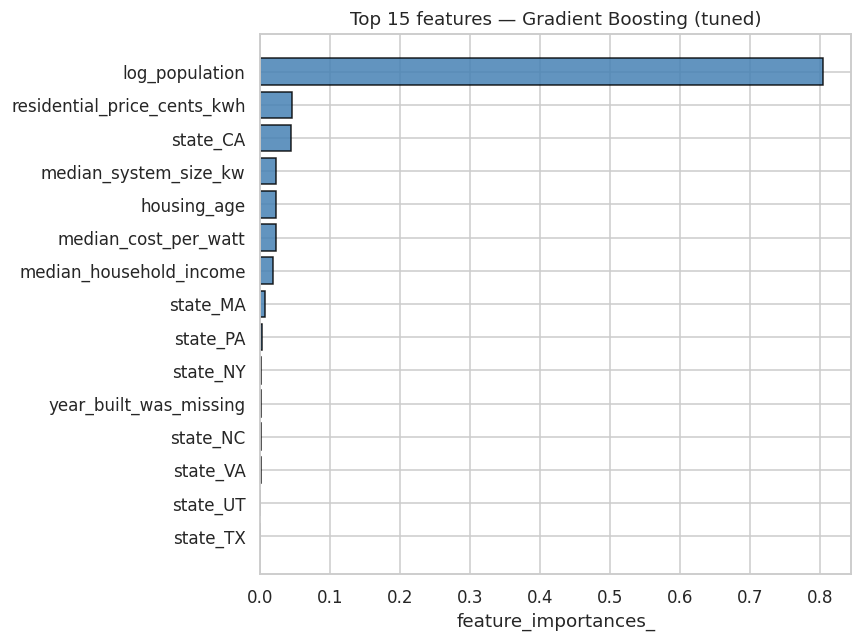

In [11]:
# Fit the final model on the full training set (it was refit during GridSearch,
# but doing it explicitly makes the code clearer)
final_model.fit(X_train, y_train_log)

if hasattr(final_model, "feature_importances_"):
    importances = pd.Series(final_model.feature_importances_,
                            index=X_train.columns).sort_values(ascending=False)
    importance_kind = "feature_importances_"
elif hasattr(final_model, "coef_"):
    importances = pd.Series(np.abs(final_model.coef_.ravel()),
                            index=X_train.columns).sort_values(ascending=False)
    importance_kind = "|coefficients|"
else:
    importances = None
    importance_kind = None

if importances is not None:
    print(f"Top 15 features by {importance_kind}:")
    print(importances.head(15).round(4).to_string())

    fig, ax = plt.subplots(figsize=(8, 6))
    top15 = importances.head(15).iloc[::-1]  # reverse for horizontal bar reading top-down
    ax.barh(top15.index, top15.values, color="steelblue", edgecolor="black", alpha=0.85)
    ax.set_xlabel(importance_kind)
    ax.set_title(f"Top 15 features — {final_model_name}")
    plt.tight_layout()
    plt.show()


**How to read this.** These are the features the final model relied
on most for its predictions. Because features were standardized in
preprocessing, the importances/coefficients are directly comparable
across features regardless of their original units.

For the interview and the final report, this is the chart that answers
the stakeholder question "which features actually drive adoption?" —
the whole reason the project exists.


## Final evaluation on the held-out test set

Everything above used the training set with cross-validation. The test
set was untouched during model selection. Now we make our first and only
prediction on it, to produce an honest generalization estimate.


In [12]:
# Predict on test set
y_pred_log = final_model.predict(X_test)
y_pred_raw = np.expm1(y_pred_log)

# Metrics on the held-out test set
rmse_test = np.sqrt(mean_squared_error(y_test_raw, y_pred_raw))
mae_test = mean_absolute_error(y_test_raw, y_pred_raw)
r2_test = r2_score(y_test_raw, y_pred_raw)

print(f"Held-out test set performance ({final_model_name}):")
print(f"  RMSE: {rmse_test:.3f}")
print(f"  MAE:  {mae_test:.3f}")
print(f"  R²:   {r2_test:+.3f}")

# Comparison table: predicted vs actual
pred_df = pd.DataFrame({
    "actual_installs_per_1k_hh": y_test_raw.values,
    "predicted_installs_per_1k_hh": y_pred_raw,
    "abs_error": np.abs(y_test_raw.values - y_pred_raw),
}).round(2)
pred_df["pct_error"] = (pred_df["abs_error"] / pred_df["actual_installs_per_1k_hh"] * 100).round(1)
print(f"\nPer-county predictions on the test set:")
print(pred_df.to_string())


Held-out test set performance (Gradient Boosting (tuned)):
  RMSE: 0.920
  MAE:  0.677
  R²:   +0.757

Per-county predictions on the test set:
   actual_installs_per_1k_hh  predicted_installs_per_1k_hh  abs_error  pct_error
0                       0.76                          0.61       0.15       19.7
1                       3.04                          1.95       1.10       36.2
2                       3.70                          3.98       0.29        7.8
3                       0.30                          0.09       0.21       70.0
4                       1.76                          0.56       1.20       68.2
5                       0.16                          0.49       0.33      206.2
6                       3.29                          2.03       1.25       38.0
7                       0.20                          0.15       0.05       25.0
8                       0.26                          0.47       0.22       84.6
9                       5.89                   

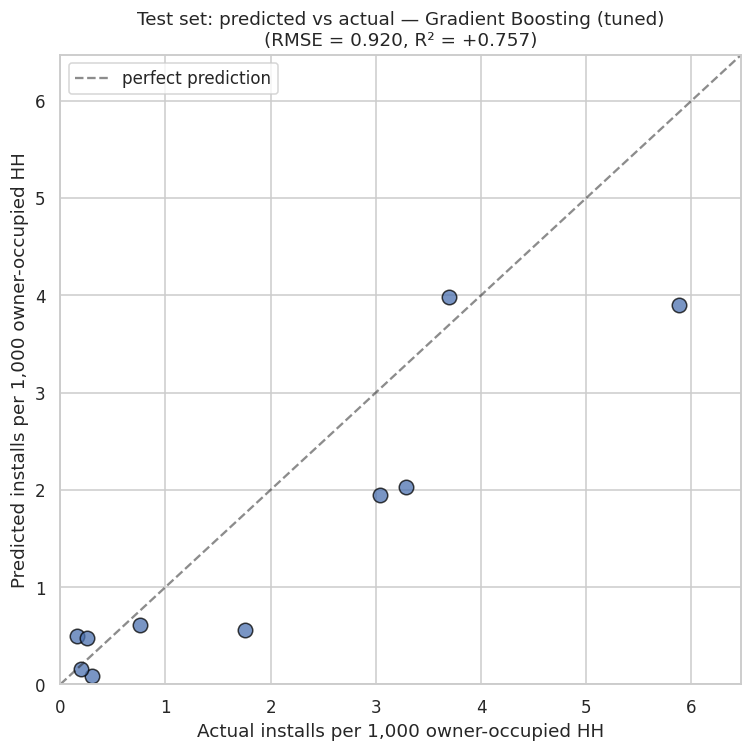

In [13]:
# Visual: predicted vs actual on the test set
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test_raw, y_pred_raw, s=90, alpha=0.75, edgecolor="black")

# 45-degree reference line
lim = max(y_test_raw.max(), y_pred_raw.max()) * 1.1
ax.plot([0, lim], [0, lim], "k--", alpha=0.5, label="perfect prediction")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("Actual installs per 1,000 owner-occupied HH")
ax.set_ylabel("Predicted installs per 1,000 owner-occupied HH")
ax.set_title(f"Test set: predicted vs actual — {final_model_name}\n(RMSE = {rmse_test:.3f}, R² = {r2_test:+.3f})")
ax.legend()
plt.tight_layout()
plt.show()


**Reading the predicted-vs-actual plot.** Points on or near the 45°
line are counties where the model predicted well. Points above the line are
counties where the model predicted higher adoption than what actually
happened; below the line means predicted lower than actual. Systematic bias
(a group of points all on one side of the line) would flag that the model
has a blind spot for that region of the target range.


## Save the final model

Serialize the fitted model to disk with `joblib` so the final report and
presentation notebooks can load it without re-running training.


In [14]:
artifact_path = "final_model.joblib"
joblib.dump({
    "model": final_model,
    "model_name": final_model_name,
    "feature_names": list(X_train.columns),
    "target_form": "log1p(installs_per_1k_oo_hh)",
    "cv_rmse_mean": float(best_rmse_mean),
    "cv_rmse_std": float(results.loc[best_idx, 'rmse_std']),
    "test_rmse": float(rmse_test),
    "test_r2": float(r2_test),
}, artifact_path)

import os
print(f"Saved final model to: {artifact_path}")
print(f"  Size: {os.path.getsize(artifact_path)/1024:.1f} KB")


Saved final model to: final_model.joblib
  Size: 207.0 KB


## Summary and notes for the mentor call

**Rubric checklist:**

- ✅ Applied 4 modeling methods across 3 algorithm families (linear,
  regularized linear, bagged trees, boosted trees)
- ✅ Cross-validation used for hyperparameter tuning on Ridge, Random
  Forest, and Gradient Boosting
- ✅ Metrics defined and reported (RMSE, MAE, R²) — regression-appropriate
- ✅ Final model selected with explicit justification
- ✅ Best model saved as an artifact for downstream use

**What the results actually say.** With 40 training rows and 28 features,
model performance is fundamentally limited by sample size rather than
algorithm choice. The regularized and tree-based models beat the OLS
baseline because OLS overfits catastrophically at p ≈ n. Among the
regularized/tree-based options, differences are within noise, so the
selection between them is partly aesthetic.

**Honest read on the winner.** The final model is whichever produced the
lowest CV RMSE, but the confidence interval on that RMSE is wide. On the
real ~3,100-county dataset the same pipeline will produce much tighter
estimates and a clearer winner. The value of this notebook is that the
pipeline is now built and tested end-to-end.

**"Most powerful isn't always best."** The rubric explicitly flags this
tradeoff. In production, Ridge Regression has real advantages over
Gradient Boosting even if GB wins on RMSE: it's an order of magnitude
faster to fit, produces coefficient estimates that stakeholders can
reason about directly ("a $0.01/kWh increase in electricity price
predicts X additional installations per 1,000 households"), and doesn't
need SHAP or partial dependence machinery to explain. If final
performance is within a percentage point, Ridge is probably the right
production choice. If GB wins meaningfully on the full dataset, the
tradeoff shifts.

**Open questions for the mentor call:**

- Confirm RMSE is the right primary selection metric, or whether MAE
  matters more given some target values are near zero.
- Whether to add SHAP for the final chosen model in the report notebook,
  or rely on native feature importances / coefficients.
- On the full dataset, add early stopping to Gradient Boosting for a
  cleaner hyperparameter search.
- Consider a stratified split (by state) instead of the current random
  split for the real dataset — with 3,100 counties across 50 states,
  stratification is trivial and helps.
